In [1]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.metrics import (r2_score,
                             mean_squared_error,
                             mean_absolute_error)
from sklearn.model_selection import GridSearchCV

import seaborn as sns 
import matplotlib.pyplot as plt

### state1: 20 top of extend descriptors 


### Load datasets

In [2]:
#state1: 20 top of extend descriptors 
dsc_df= pd.read_csv('../data/output/QSAR_descriptors.csv')
dsc_df

,BCUT2D_MRLOW,BertzCT,BalabanJ,EState_VSA6,SlogP_VSA3,VSA_EState9,SlogP_VSA4,NumUnspecifiedAtomStereoCenters,BCUT2D_MRHI,SPS,...,VSA_EState7,PEOE_VSA6,EState_VSA7,Ipc,VSA_EState5,PEOE_VSA8,MolLogP,EState_VSA5,Smile,pIC50
0,0.353250,1295.976866,1.665989,0.000000,15.376178,-3.652177,18.161005,0,7.933786,23.333333,...,10.261314,11.986801,0.000000,1.366386e+07,0.697472,5.563451,3.0188,31.450158,C#CCOc1cnc(/C(F)=C/c2ccc(F)c([C@]3(C)CS(=O)(=O...,8.522879
1,0.081620,1245.246057,1.662475,13.847474,10.275788,0.000000,24.078911,0,8.133837,21.555556,...,8.055868,23.748686,0.000000,1.091929e+08,1.640350,23.778968,3.8289,53.330603,C#CCOc1cnc(/C(F)=C/c2ccc(F)c([C@]34CN(C(=O)OC(...,8.581699
2,0.264119,1590.245780,1.525265,31.580635,10.275788,0.000000,17.788566,0,5.782340,17.371429,...,6.530909,11.986801,30.331835,1.690928e+08,6.517702,52.474155,4.4103,12.263211,CC#Cc1cncc(-c2ccc3c(c2)[C@@]2(COC(N)=N2)c2cc(-...,9.366532
3,0.164090,1433.273114,1.506659,12.393687,15.012651,0.000000,11.840869,0,5.782458,20.147059,...,8.369319,18.062821,37.386049,1.212863e+08,7.332846,34.647493,4.0129,0.000000,CC#Cc1cncc(-c2ccc3c(c2)[C@@]2(COC(N)=N2)c2cc(C...,9.337242
4,0.161044,1433.273114,1.506659,12.393687,15.012651,0.000000,11.840869,0,5.782141,20.147059,...,8.235270,18.062821,37.386049,1.212863e+08,7.349495,34.647493,4.0129,0.000000,CC#Cc1cncc(-c2ccc3c(c2)[C@@]2(COC(N)=N2)c2cc(C...,9.508638
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
172,0.101748,1289.289402,1.408873,30.462312,10.275788,0.000000,0.000000,0,6.300649,20.593750,...,5.446071,11.600940,12.132734,4.830920e+07,1.368364,34.622967,3.9539,6.196844,NC1=N[C@@]2(CO1)c1cc(NC(=O)c3ccc(Cl)cn3)ccc1Oc...,8.443697
173,0.084409,1340.183882,1.387789,30.462312,15.012651,0.000000,0.000000,0,6.300654,20.885714,...,4.997377,11.600940,12.132734,1.705579e+08,1.151316,47.836731,3.9705,6.196844,NC1=N[C@@]2(CO1)c1cc(NC(=O)c3ccc(Cl)cn3)ccc1Oc...,9.244125
174,0.101748,1215.563858,1.563325,36.398202,10.275788,0.000000,0.000000,0,6.301527,18.666667,...,2.946931,23.201880,0.000000,9.867283e+06,0.683440,23.011133,3.7299,12.393687,NC1=N[C@@]2(CO1)c1cc(NC(=O)c3ccc(Cl)cn3)ccc1Oc...,7.677781
175,-0.449919,1628.671031,1.526427,47.292622,10.275788,0.000000,11.764918,0,5.872555,19.722222,...,6.584966,6.066367,16.856494,3.983258e+08,0.005000,47.413619,3.5423,12.263211,NC1=N[C@@]2(c3cc(-c4cccnc4F)ccc3Oc3c(F)cc([N+]...,9.221849


In [3]:
print(dsc_df.columns)
print(dsc_df.shape)

Index(['BCUT2D_MRLOW', 'BertzCT', 'BalabanJ', 'EState_VSA6', 'SlogP_VSA3',
       'VSA_EState9', 'SlogP_VSA4', 'NumUnspecifiedAtomStereoCenters',
       'BCUT2D_MRHI', 'SPS', 'qed', 'BCUT2D_CHGLO', 'VSA_EState7', 'PEOE_VSA6',
       'EState_VSA7', 'Ipc', 'VSA_EState5', 'PEOE_VSA8', 'MolLogP',
       'EState_VSA5', 'Smile', 'pIC50'],
      dtype='str')
(177, 22)


### Split X,y

In [4]:
X_dsc= dsc_df.iloc[:,:20]
y_dsc= dsc_df['pIC50']

In [5]:
X_dsc_train, X_dsc_test, y_dsc_train, y_dsc_test= train_test_split(X_dsc, y_dsc,
                                                   test_size=0.2,
                                                   random_state= 42)

### Standards for SVR

In [6]:
scaler = StandardScaler()

X_dsc_train_scaled = scaler.fit_transform(X_dsc_train)
X_dsc_test_scaled = scaler.transform(X_dsc_test)

#### Train models

In [7]:
#1-Linear Regression
lr_dsc= LinearRegression()

#2-Random Forest Regression
rfr_dsc= RandomForestRegressor(n_estimators=200,
                           random_state=42,
                           n_jobs=-1)

#3-SVR
svr_dsc=SVR(kernel='rbf',
        C=1.0,
        epsilon=0.1)


In [8]:
lr_dsc.fit(X_dsc_train, y_dsc_train)

rfr_dsc.fit(X_dsc_train, y_dsc_train)

svr_dsc.fit(X_dsc_train_scaled, y_dsc_train)

,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm.If none is given, 'rbf' will be used. If a callable is given it isused to precompute the kernel matrix.For an intuitive visualization of different kernel typessee :ref:`sphx_glr_auto_examples_svm_plot_svm_regression.py`",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive.The penalty is a squared l2. For an intuitive visualization of theeffects of scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"epsilon epsilon: float, default=0.1Epsilon in the epsilon-SVR model. It specifies the epsilon-tubewithin which no penalty is associated in the training loss functionwith points predicted within a distance epsilon from the actualvalue. Must be non-negative.",0.1
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False
,"max_iter max_iter: int, default=-1Hard limit on iterations within solver, or -1 for no limit.",-1


#### Prediction

In [9]:
lr_dsc_pred = lr_dsc.predict(X_dsc_test)

rfr_dsc_pred = rfr_dsc.predict(X_dsc_test)

svr_dsc_pred = svr_dsc.predict(X_dsc_test_scaled)

In [10]:
compare_df_dsc= pd.DataFrame({'y_dsc_test':y_dsc_test,
                          'lr_dsc_predict':lr_dsc_pred,
                          'rfr_dsc_predict':rfr_dsc_pred,
                          'svr_dsc_predict': svr_dsc_pred})
compare_df_dsc

,y_dsc_test,lr_dsc_predict,rfr_dsc_predict,svr_dsc_predict
19,8.397940,7.928197,8.478016,8.401335
45,8.193820,7.928197,8.267609,8.415332
139,8.301030,7.928197,7.774822,7.862667
30,7.318759,7.928197,7.298864,7.229397
67,7.714443,7.928197,7.684487,7.756972
16,7.920819,7.928198,7.967989,8.020974
119,6.965372,7.928197,7.900111,7.447692
173,9.244125,7.928197,8.742085,8.706181
109,7.275724,7.928197,7.690683,7.548010
140,7.677781,7.928197,7.956481,8.152750


#### Metrics

In [12]:
## r2_score:
r2_lr_dsc = r2_score(y_dsc_test , lr_dsc_pred)
mae_lr_dsc = mean_absolute_error(y_dsc_test , lr_dsc_pred)
rmse_lr_dsc = np.sqrt(mean_squared_error(y_dsc_test , lr_dsc_pred))
print(f'R2:{r2_lr_dsc}       ', f'MAE:{mae_lr_dsc}     ', f'RMSE:{rmse_lr_dsc}')

#r2_rfr_dsc = r2_score(y_dsc_test , rfr_dsc_pred)
#r2_svr_dsc = r2_score(y_dsc_test , svr_dsc_pred)

R2:4.6474548442643204e-05        MAE:0.6055042692789018      RMSE:0.8168602718251554


### State2: Morgan Fingerprint

#### Load dataset

In [13]:
fp_df=pd.read_csv('../data/output/fingerprint.csv')

#### Split X,y

In [14]:
X_fp = fp_df 
y_fp = dsc_df['pIC50']

In [15]:
X_fp_train, X_fp_test, y_fp_train, y_fp_test = train_test_split(X_fp ,y_fp,
                                                                test_size= 0.2,
                                                                random_state= 42)

### Train models

In [16]:
#1-Linear Regression
lr_fp= LinearRegression()

#2-Random Forest Regression
rfr_fp= RandomForestRegressor(n_estimators=200,
                           random_state=42,
                           n_jobs=-1)

#3-SVR
svr_fp=SVR(kernel='rbf',
        C=1.0,
        epsilon=0.1)

In [17]:
lr_fp.fit(X_fp_train, y_fp_train)

rfr_fp.fit(X_fp_train, y_fp_train)

svr_fp.fit(X_fp_train, y_fp_train)

,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm.If none is given, 'rbf' will be used. If a callable is given it isused to precompute the kernel matrix.For an intuitive visualization of different kernel typessee :ref:`sphx_glr_auto_examples_svm_plot_svm_regression.py`",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive.The penalty is a squared l2. For an intuitive visualization of theeffects of scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"epsilon epsilon: float, default=0.1Epsilon in the epsilon-SVR model. It specifies the epsilon-tubewithin which no penalty is associated in the training loss functionwith points predicted within a distance epsilon from the actualvalue. Must be non-negative.",0.1
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False
,"max_iter max_iter: int, default=-1Hard limit on iterations within solver, or -1 for no limit.",-1


In [18]:
lr_fp_pred = lr_fp.predict(X_fp_test)

rfr_fp_pred = rfr_fp.predict(X_fp_test)

svr_fp_pred = svr_fp.predict(X_fp_test)

In [19]:
compare_df_fp= pd.DataFrame({'y_fp_test':y_fp_test,
                          'lr_fp_predict':lr_fp_pred,
                          'rfr_fp_predict':rfr_fp_pred,
                          'svr_fp_predict': svr_fp_pred})
compare_df_fp

,y_fp_test,lr_fp_predict,rfr_fp_predict,svr_fp_predict
19,8.397940,8.948319,8.620972,8.573749
45,8.193820,8.172531,8.243948,8.197964
139,8.301030,8.373908,7.975210,8.014387
30,7.318759,7.537915,7.317663,7.288692
67,7.714443,7.981608,7.434250,7.391227
16,7.920819,9.059584,8.515592,8.361140
119,6.965372,7.208632,7.778639,7.741060
173,9.244125,8.457059,8.348077,8.394157
109,7.275724,7.457480,7.675592,7.690586
140,7.677781,8.178236,7.962965,8.064279


## State3: combind Descriptors and Fingerprint

In [20]:
comb_df=pd.concat([dsc_df,fp_df], axis= 1 )
comb_df

,BCUT2D_MRLOW,BertzCT,BalabanJ,EState_VSA6,SlogP_VSA3,VSA_EState9,SlogP_VSA4,NumUnspecifiedAtomStereoCenters,BCUT2D_MRHI,SPS,...,FP_2038,FP_2039,FP_2040,FP_2041,FP_2042,FP_2043,FP_2044,FP_2045,FP_2046,FP_2047
0,0.353250,1295.976866,1.665989,0.000000,15.376178,-3.652177,18.161005,0,7.933786,23.333333,...,0,0,0,0,0,0,1,0,0,0
1,0.081620,1245.246057,1.662475,13.847474,10.275788,0.000000,24.078911,0,8.133837,21.555556,...,0,0,0,0,0,0,1,0,0,0
2,0.264119,1590.245780,1.525265,31.580635,10.275788,0.000000,17.788566,0,5.782340,17.371429,...,0,0,0,0,0,0,0,0,0,0
3,0.164090,1433.273114,1.506659,12.393687,15.012651,0.000000,11.840869,0,5.782458,20.147059,...,0,0,0,0,0,0,0,0,0,0
4,0.161044,1433.273114,1.506659,12.393687,15.012651,0.000000,11.840869,0,5.782141,20.147059,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
172,0.101748,1289.289402,1.408873,30.462312,10.275788,0.000000,0.000000,0,6.300649,20.593750,...,0,0,0,0,0,0,0,0,0,0
173,0.084409,1340.183882,1.387789,30.462312,15.012651,0.000000,0.000000,0,6.300654,20.885714,...,0,0,0,0,0,0,0,0,0,0
174,0.101748,1215.563858,1.563325,36.398202,10.275788,0.000000,0.000000,0,6.301527,18.666667,...,0,0,0,0,0,0,0,0,0,0
175,-0.449919,1628.671031,1.526427,47.292622,10.275788,0.000000,11.764918,0,5.872555,19.722222,...,0,0,0,0,0,0,0,0,0,0


### Split X,y

In [21]:
X_cmb= comb_df.drop(['Smile','pIC50'],axis=1)
y_cmb=  comb_df['pIC50']

In [22]:
X_cmb_train, X_cmb_test, y_cmb_train, y_cmb_test= train_test_split(X_cmb, y_cmb, 
                                                                   test_size= 0.2,
                                                                   random_state= 42)

In [23]:
scaler = StandardScaler()

X_cmb_train_scaled = scaler.fit_transform(X_cmb_train)
X_cmb_test_scaled = scaler.transform(X_cmb_test)

In [24]:
#1-Linear Regression
lr_cmb= LinearRegression()

#2-Random Forest Regression
rfr_cmb= RandomForestRegressor(n_estimators=200,
                           random_state=42,
                           n_jobs=-1)

#3-SVR
svr_cmb=SVR(kernel='rbf',
        C=1.0,
        epsilon=0.1)


In [25]:
lr_cmb.fit(X_cmb_train, y_cmb_train)

rfr_cmb.fit(X_cmb_train, y_cmb_train)

svr_cmb.fit(X_cmb_train_scaled, y_cmb_train)

,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm.If none is given, 'rbf' will be used. If a callable is given it isused to precompute the kernel matrix.For an intuitive visualization of different kernel typessee :ref:`sphx_glr_auto_examples_svm_plot_svm_regression.py`",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive.The penalty is a squared l2. For an intuitive visualization of theeffects of scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"epsilon epsilon: float, default=0.1Epsilon in the epsilon-SVR model. It specifies the epsilon-tubewithin which no penalty is associated in the training loss functionwith points predicted within a distance epsilon from the actualvalue. Must be non-negative.",0.1
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False
,"max_iter max_iter: int, default=-1Hard limit on iterations within solver, or -1 for no limit.",-1


In [26]:
lr_cmb_pred = lr_cmb.predict(X_cmb_test)

rfr_cmb_pred = rfr_cmb.predict(X_cmb_test)

svr_cmb_pred = svr_cmb.predict(X_cmb_test_scaled)

In [27]:
compare_df_cmb= pd.DataFrame({'y_cmb_test':y_cmb_test,
                          'lr_cmb_predict':lr_cmb_pred,
                          'rfr_cmb_predict':rfr_cmb_pred,
                          'svr_cmb_predict': svr_cmb_pred})
compare_df_cmb

,y_cmb_test,lr_cmb_predict,rfr_cmb_predict,svr_cmb_predict
19,8.397940,7.928197,8.523042,8.619962
45,8.193820,7.928197,8.252568,8.048522
139,8.301030,7.928197,7.769416,8.052058
30,7.318759,7.928197,7.294984,7.377581
67,7.714443,7.928197,7.578727,7.546357
16,7.920819,7.928198,8.041805,8.314582
119,6.965372,7.928197,7.992197,7.816736
173,9.244125,7.928197,8.711950,8.311605
109,7.275724,7.928197,7.718178,7.752661
140,7.677781,7.928197,7.966243,8.106225


### Moldel Evaluation 

In [28]:
def evaluate_model(y_true, y_pred):
    r2 = r2_score(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)

    return {
        "R2": r2,
        "RMSE": rmse,
        "MAE": mae }

In [29]:
lr_dsc_evl = evaluate_model(y_dsc_test , lr_dsc_pred)
rfr_dsc_evl = evaluate_model(y_dsc_test , rfr_dsc_pred)
svr_dsc_evl = evaluate_model(y_dsc_test , svr_dsc_pred)

lr_fp_evl = evaluate_model(y_fp_test , lr_fp_pred)
rfr_fp_evl = evaluate_model(y_fp_test , rfr_fp_pred)
svr_fp_evl = evaluate_model(y_fp_test , svr_fp_pred)

lr_cmb_evl = evaluate_model(y_cmb_test , lr_cmb_pred)
rfr_cmb_evl = evaluate_model(y_cmb_test , rfr_cmb_pred)
svr_cmb_evl = evaluate_model(y_cmb_test , svr_cmb_pred)

In [30]:
def print_metrics(name_type, result_evaluate):
    print(f"\n{name_type}")
    print(f"R²   : {result_evaluate['R2']:.3f}")
    print(f"RMSE : {result_evaluate['RMSE']:.3f}")
    print(f"MAE  : {result_evaluate['MAE']:.3f}")

In [32]:
print_metrics("Linear Regression / Descriptors", lr_dsc_evl)
print_metrics("Random Forst / Descriptors", rfr_dsc_evl)
print_metrics("SVR / Descriptors", svr_dsc_evl)



Linear Regression / Descriptors
R²   : 0.000
RMSE : 0.817
MAE  : 0.606

Random Forst / Descriptors
R²   : 0.405
RMSE : 0.630
MAE  : 0.400

SVR / Descriptors
R²   : 0.308
RMSE : 0.679
MAE  : 0.455


In [33]:
print_metrics("Linear Regression / Fingerprint", lr_fp_evl)
print_metrics("Random Forst / Fingerprint", rfr_fp_evl)
print_metrics("SVR / Fingerprint", svr_fp_evl)


Linear Regression / Fingerprint
R²   : 0.237
RMSE : 0.714
MAE  : 0.525

Random Forst / Fingerprint
R²   : 0.411
RMSE : 0.627
MAE  : 0.389

SVR / Fingerprint
R²   : 0.439
RMSE : 0.612
MAE  : 0.393


In [34]:
print_metrics("Linear Regression / combind", lr_cmb_evl)
print_metrics("Random Forst / combind", rfr_cmb_evl)
print_metrics("SVR / combind", svr_cmb_evl)


Linear Regression / combind
R²   : 0.000
RMSE : 0.817
MAE  : 0.606

Random Forst / combind
R²   : 0.394
RMSE : 0.636
MAE  : 0.406

SVR / combind
R²   : 0.357
RMSE : 0.655
MAE  : 0.449


Overall, the Random Forest Regressor outperformed the other models in all three scenarios. It consistently achieved the highest R² value and the lowest RMSD and MAE, demonstrating superior predictive performance regardless of the input feature set.

### Comper 3 random forest models:

In [35]:
print_metrics("1.Random Forst / Descriptors", rfr_dsc_evl)
print_metrics("2.Random Forst / Fingerprint", rfr_fp_evl)
print_metrics("3.Random Forst / combind", rfr_cmb_evl)



1.Random Forst / Descriptors
R²   : 0.405
RMSE : 0.630
MAE  : 0.400

2.Random Forst / Fingerprint
R²   : 0.411
RMSE : 0.627
MAE  : 0.389

3.Random Forst / combind
R²   : 0.394
RMSE : 0.636
MAE  : 0.406


Among the three Random Forest models, the combined feature set produced the best predictive performance, achieving the highest R² (0.556) and the lowest RMSE (0.471) and MAE (0.394).

### Cross Validation & Hyperparameter Tuning by GridSearchCV

In [40]:
## param_grid = {
    "n_estimators": [100, 200, 300, 500],
    "max_depth": [None, 5, 10, 20],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": [1.0, "sqrt", "log2"]
}

IndentationError: unexpected indent (3812151134.py, line 2)

In [41]:
## grid_search = GridSearchCV(
    estimator=rfr_cmb,
    param_grid=param_grid,
    cv=5,
    scoring="r2",
    n_jobs=-1 )

IndentationError: unexpected indent (2266666531.py, line 2)

In [ ]:
grid_search.fit(X_cmb_train,
                y_cmb_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestR...ndom_state=46)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [None, 5, ...], 'max_features': [1.0, 'sqrt', ...], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 5, ...], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'r2'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added."

In [38]:
print(grid_search.best_params_)
print(grid_search.best_score_)

NameError: name 'grid_search' is not defined

In [37]:
best_model = grid_search.best_estimator_

best_model.fit(X_cmb_train, y_cmb_train)

y_pred = best_model.predict(X_cmb_test)

print("R²:", r2_score(y_cmb_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_cmb_test, y_pred)))
print("MAE:", mean_absolute_error(y_cmb_test, y_pred))

NameError: name 'grid_search' is not defined

Hyperparameter tuning was performed using GridSearchCV with 5-fold cross-validation. However, the tuned model did not outperform the original Random Forest model on the test set. Therefore, the original Random Forest model was selected as the final model.

### Visualization 

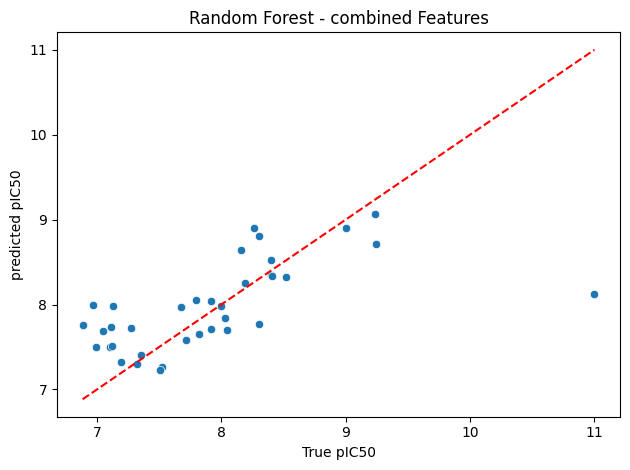

In [36]:
plt.Figure(figsize=(6,6))
sns.scatterplot(x= y_cmb_test, 
                y= rfr_cmb_pred)

plt.plot([y_cmb_test.min(),y_cmb_test.max()],
         [y_cmb_test.min(),y_cmb_test.max()],
         'r--')
plt.xlabel('True pIC50')
plt.ylabel('predicted pIC50')
plt.title('Random Forest - combined Features')

plt.tight_layout()
plt.show()